In [ ]:
# Tarea 3 — PyTorch Fashion MNIST
**Nombre:** [Alexandra Padrón]
**Cédula:** [30715017]

=== PyTorch Fashion MNIST ===
1. Crear nueva red neuronal
2. Cargar red desde archivo


Seleccione una opción:  1



--- Configuración de la Red ---


Clasificación (1: Original 10 clases, 2: Simplificada 4 clases):  2
Tipo de red (1: Rectangular, 2: Convolucional):  2
Número de capas ocultas (por defecto 2):  2



--- Optimizaciones ---


¿Usar Batch Normalization? (s/n):  s
¿Usar Dropout (20%)? (s/n):  s



¡Red creada exitosamente!

--- MENÚ PRINCIPAL ---
Red actual: Convolucional | Clasificación: simplified
Capas ocultas: 2 | Épocas acumuladas: 0
1. Entrenar la red
2. Probar la red
3. Guardar la red (*.pth)
4. Salir


Opción:  1
Número de épocas (por defecto 10):  10
Learning Rate (por defecto 0.001):  0.001
Optimizador (1: Adam, 2: SGD):  1



Entrenando... (esto puede tardar un poco)
Época [1/10], Loss: 0.1180
Época [2/10], Loss: 0.0868
Época [3/10], Loss: 0.0771
Época [4/10], Loss: 0.0692
Época [5/10], Loss: 0.0625
Época [6/10], Loss: 0.0590
Época [7/10], Loss: 0.0543
Época [8/10], Loss: 0.0518
Época [9/10], Loss: 0.0477
Época [10/10], Loss: 0.0461


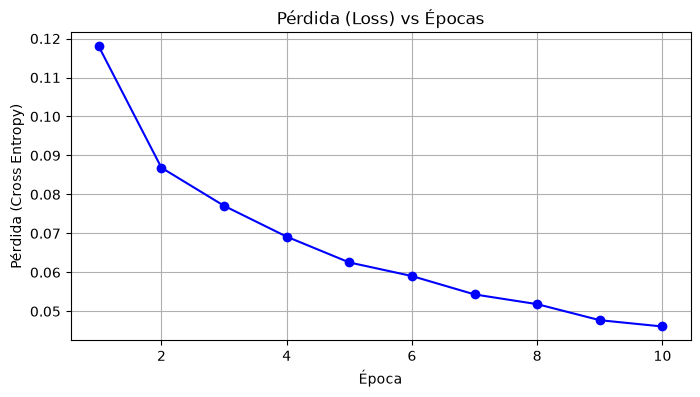


--- MENÚ PRINCIPAL ---
Red actual: Convolucional | Clasificación: simplified
Capas ocultas: 2 | Épocas acumuladas: 10
1. Entrenar la red
2. Probar la red
3. Guardar la red (*.pth)
4. Salir


Opción:  3
Nombre del archivo para guardar (ej. pytorch_fashion_1_original_rectangular.pth):  pytorch_fashion_1_simplified_convolutional.pth



Modelo guardado en: pytorch_fashion_1_simplified_convolutional.pth

--- MENÚ PRINCIPAL ---
Red actual: Convolucional | Clasificación: simplified
Capas ocultas: 2 | Épocas acumuladas: 10
1. Entrenar la red
2. Probar la red
3. Guardar la red (*.pth)
4. Salir


Opción:  4


Saliendo...


In [5]:
# --- IMPORTACIONES ---
import torch
from torch import nn, optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, ConfusionMatrixDisplay
import os

# Configuración del dispositivo (usa GPU si está disponible, si no CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# --- LÓGICA PRINCIPAL ---
def get_dataloaders(batch_size=64):
    transform = transforms.ToTensor()
    train_dataset = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
    test_dataset = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)
    
    train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    return train_loader, test_loader

def simplify_labels(y):
    # Mapping para clases simplificadas
    # 0 = Top, 1 = Bottom, 2 = Footwear, 3 = Bag
    mapping = {0: 0, 1: 1, 2: 0, 3: 1, 4: 0, 5: 2, 6: 0, 7: 2, 8: 3, 9: 2}
    return torch.tensor([mapping[val.item()] for val in y], device=y.device)

def build_model(hyperparams):
    net_type = hyperparams['net_type']
    L = hyperparams['hidden_layers']
    task = hyperparams['classification']
    use_batchnorm = hyperparams.get('batchnorm', False)
    use_dropout = hyperparams.get('dropout', False)

    in_features = 784
    out_features = 10 if task == 'original' else 4

    layers = [nn.Flatten()]
    current_in = in_features

    if net_type == 'rectangular':
        neurons = hyperparams.get('neurons_per_layer', 512)
        for _ in range(L):
            layers.append(nn.Linear(current_in, neurons))
            if use_batchnorm: layers.append(nn.BatchNorm1d(neurons))
            layers.append(nn.ReLU())
            if use_dropout: layers.append(nn.Dropout(0.2))
            current_in = neurons
    else: # convolucional (embudo)
        for i in range(1, L + 1):
            neurons = round(in_features + (out_features - in_features) * i / (L + 1))
            layers.append(nn.Linear(current_in, neurons))
            if use_batchnorm: layers.append(nn.BatchNorm1d(neurons))
            layers.append(nn.ReLU())
            if use_dropout: layers.append(nn.Dropout(0.2))
            current_in = neurons

    layers.append(nn.Linear(current_in, out_features))
    return nn.Sequential(*layers).to(device)

def train_model(model, train_loader, epochs, lr, optimizer_name, task, weight_decay=0):
    criterion = nn.CrossEntropyLoss()
    if optimizer_name == 'adam':
        optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        optimizer = optim.SGD(model.parameters(), lr=lr, weight_decay=weight_decay)

    model.train()
    loss_history = []
    
    print("\nEntrenando... (esto puede tardar un poco)")
    for epoch in range(epochs):
        epoch_loss = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            if task == 'simplified':
                labels = simplify_labels(labels)
                
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
            
        avg_loss = epoch_loss / len(train_loader)
        loss_history.append(avg_loss)
        print(f"Época [{epoch+1}/{epochs}], Loss: {avg_loss:.4f}")
        
    return loss_history

def test_model(model, test_loader, task):
    model.eval()
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            if task == 'simplified':
                labels = simplify_labels(labels)
                
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_targets.extend(labels.cpu().numpy())
            
    acc = accuracy_score(all_targets, all_preds)
    prec = precision_score(all_targets, all_preds, average='macro', zero_division=0)
    rec = recall_score(all_targets, all_preds, average='macro', zero_division=0)
    cm = confusion_matrix(all_targets, all_preds)
    
    return acc, prec, rec, cm

def save_model(model, hyperparams, path):
    torch.save({
        "state_dict": model.state_dict(),
        "hyperparameters": hyperparams
    }, path)
    print(f"\nModelo guardado en: {path}")

def load_model(path):
    data = torch.load(path, map_location=device, weights_only=False)
    hyperparams = data['hyperparameters']
    model = build_model(hyperparams)
    model.load_state_dict(data['state_dict'])
    return model, hyperparams

def main():
    model = None
    hyperparams = None
    train_loader, test_loader = get_dataloaders()
    
    print("=== PyTorch Fashion MNIST ===")
    print("1. Crear nueva red neuronal")
    print("2. Cargar red desde archivo")
    opt = input("Seleccione una opción: ")
    
    if opt == '1':
        print("\n--- Configuración de la Red ---")
        task = 'original' if input("Clasificación (1: Original 10 clases, 2: Simplificada 4 clases): ") == '1' else 'simplified'
        net_type = 'rectangular' if input("Tipo de red (1: Rectangular, 2: Convolucional): ") == '1' else 'convolucional'
        hidden_layers = int(input("Número de capas ocultas (por defecto 2): ") or 2)
        
        hyperparams = {
            'classification': task,
            'net_type': net_type,
            'hidden_layers': hidden_layers,
            'epochs': 0
        }
        
        if net_type == 'rectangular':
            hyperparams['neurons_per_layer'] = int(input("Neuronas por capa (por defecto 512): ") or 512)
            
        print("\n--- Optimizaciones ---")
        hyperparams['batchnorm'] = input("¿Usar Batch Normalization? (s/n): ").lower() == 's'
        hyperparams['dropout'] = input("¿Usar Dropout (20%)? (s/n): ").lower() == 's'
        
        model = build_model(hyperparams)
        print("\n¡Red creada exitosamente!")
        
    elif opt == '2':
        path = input("Ruta del archivo .pth: ")
        model, hyperparams = load_model(path)
        print("\n¡Red cargada exitosamente!")
    else:
        return

    while True:
        print("\n--- MENÚ PRINCIPAL ---")
        print(f"Red actual: {hyperparams['net_type'].capitalize()} | Clasificación: {hyperparams['classification']}")
        print(f"Capas ocultas: {hyperparams['hidden_layers']} | Épocas acumuladas: {hyperparams['epochs']}")
        print("1. Entrenar la red")
        print("2. Probar la red")
        print("3. Guardar la red (*.pth)")
        print("4. Salir")
        
        choice = input("Opción: ")
        
        if choice == '1':
            epochs = int(input("Número de épocas (por defecto 10): ") or 10)
            lr = float(input("Learning Rate (por defecto 0.001): ") or 0.001)
            optimizer_name = 'adam' if input("Optimizador (1: Adam, 2: SGD): ") == '1' else 'sgd'
            
            loss_hist = train_model(model, train_loader, epochs, lr, optimizer_name, hyperparams['classification'])
            hyperparams['epochs'] += epochs
            
            plt.figure(figsize=(8,4))
            plt.plot(range(1, len(loss_hist)+1), loss_hist, marker='o', color='blue')
            plt.title('Pérdida (Loss) vs Épocas')
            plt.xlabel('Época')
            plt.ylabel('Pérdida (Cross Entropy)')
            plt.grid(True)
            plt.show()
            
        elif choice == '2':
            print("\nEvaluando modelo...")
            acc, prec, rec, cm = test_model(model, test_loader, hyperparams['classification'])
            
            print(f"\n--- Métricas ---")
            print(f"Accuracy:  {acc:.4f}")
            print(f"Precision: {prec:.4f} (Macro)")
            print(f"Recall:    {rec:.4f} (Macro)")
            
            disp = ConfusionMatrixDisplay(confusion_matrix=cm)
            disp.plot(cmap=plt.cm.Blues)
            plt.title('Matriz de Confusión')
            plt.show()
            
        elif choice == '3':
            path = input("Nombre del archivo para guardar (ej. pytorch_fashion_1_original_rectangular.pth): ")
            save_model(model, hyperparams, path)
            
        elif choice == '4':
            print("Saliendo...")
            break

# Ejecutar menú
main()